4.1 Diagramas de barras — barplot
Muestran por defecto la media de una variable numérica para cada categoría y un intervalo (controlado por errorbar).

A) Barras básicas (media + error)

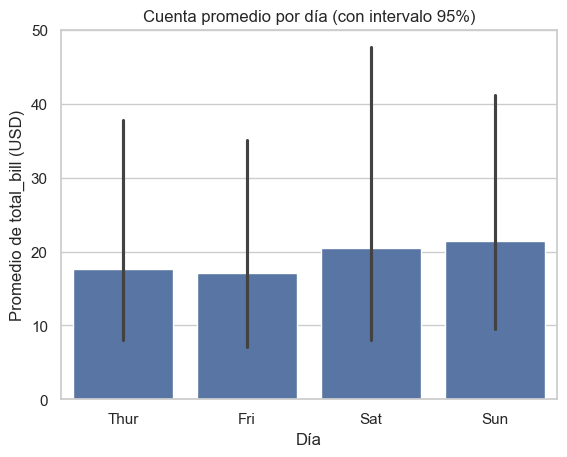

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")
tips = sns.load_dataset("tips")

sns.barplot(data=tips, x="day", y="total_bill", errorbar=("pi", 95))  # intervalo percentil 95%
plt.title("Cuenta promedio por día (con intervalo 95%)")
plt.xlabel("Día")
plt.ylabel("Promedio de total_bill (USD)")
plt.show()

B) Barras por subgrupo (hue) y distinto estimador

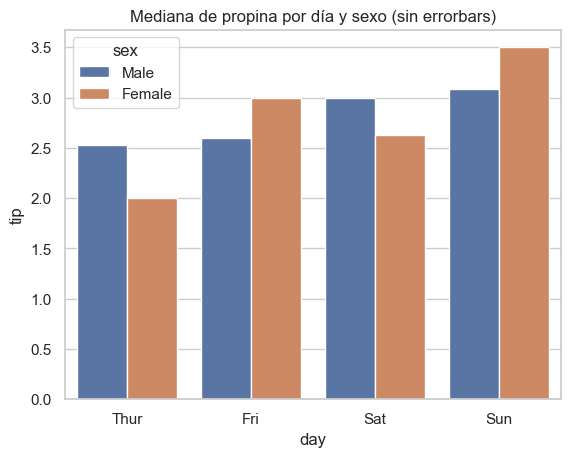

In [2]:
import seaborn as sns
import matplotlib.pyplot as plt
from numpy import median

sns.set_theme(style="whitegrid", context="notebook")
tips = sns.load_dataset("tips")

sns.barplot(
    data=tips,
    x="day", y="tip", hue="sex",
    estimator=median,                # usar la mediana en vez de media
    errorbar=None,                   # sin banda de error
    dodge=True
)
plt.title("Mediana de propina por día y sexo (sin errorbars)")
plt.show()

C) Orden y orientación

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")
titanic = sns.load_dataset("titanic").dropna(subset=["class", "fare"])

orden = ["Third", "Second", "First"]
sns.barplot(
    data=titanic, y="class", x="fare",
    order=orden, orient="h", errorbar="sd"
)
plt.title("Tarifa promedio por clase (horizontal)")
plt.xlabel("Fare promedio")
plt.ylabel("Clase")
plt.show()

Notas: errorbar admite "sd", "se", ("pi", 95), None, etc. Para proporciones, considerá countplot (frecuencias) o calcula previamente tu métrica y usa barplot.

4.2 Diagramas de cajas — boxplot
Resumen robusto de la distribución por categoría: mediana, cuartiles y outliers.

A) Boxplot básico

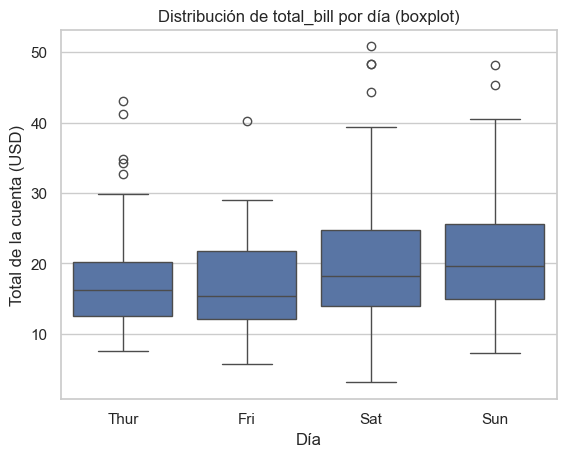

In [4]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")
tips = sns.load_dataset("tips")

sns.boxplot(data=tips, x="day", y="total_bill")
plt.title("Distribución de total_bill por día (boxplot)")
plt.xlabel("Día")
plt.ylabel("Total de la cuenta (USD)")
plt.show()

B) Boxplot por subgrupo (hue) y control de ancho/orden

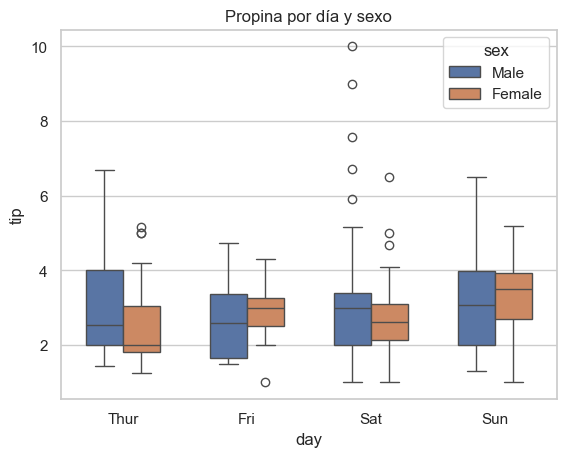

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")
tips = sns.load_dataset("tips")

orden = ["Thur", "Fri", "Sat", "Sun"]
sns.boxplot(
    data=tips,
    x="day", y="tip", hue="sex",
    order=orden,
    width=0.6
)
plt.title("Propina por día y sexo")
plt.show()

C) Boxplot horizontal (útil cuando hay muchas categorías)

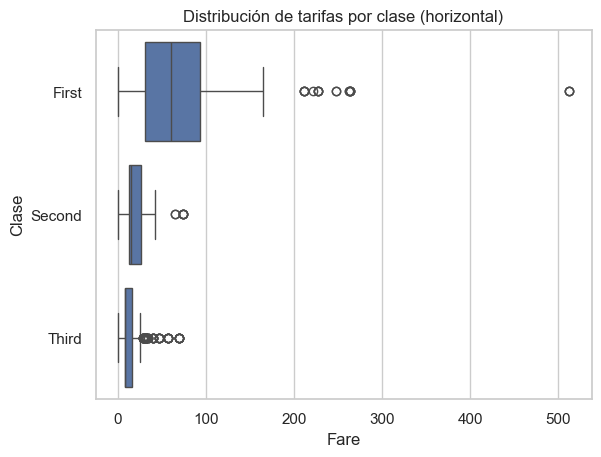

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")
titanic = sns.load_dataset("titanic").dropna(subset=["class", "fare"])

sns.boxplot(data=titanic, y="class", x="fare", orient="h")
plt.title("Distribución de tarifas por clase (horizontal)")
plt.xlabel("Fare")
plt.ylabel("Clase")
plt.show()

Consejo: si hay muchos outliers, el boxplot puede quedar “aplastado”. Probá violinplot o muestra también estadísticas numéricas.

4.3 Diagramas de violín — violinplot
Muestran la densidad de la distribución por categoría (similar a un KDE “simétrico”) junto con la mediana/cuartiles opcionalmente.

A) Violín básico

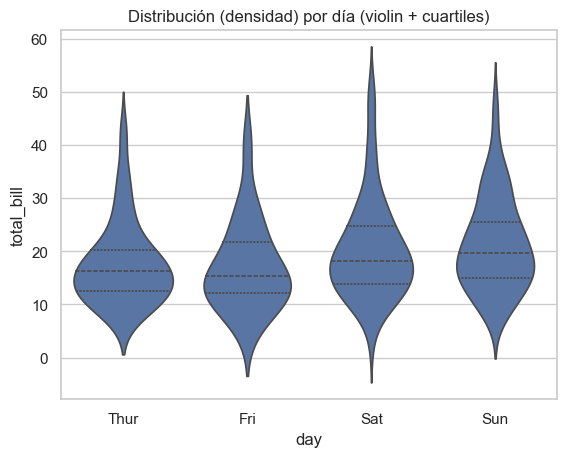

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")
tips = sns.load_dataset("tips")

sns.violinplot(data=tips, x="day", y="total_bill", inner="quartile")
plt.title("Distribución (densidad) por día (violin + cuartiles)")
plt.show()

B) Violín por subgrupo y ajuste de suavizado

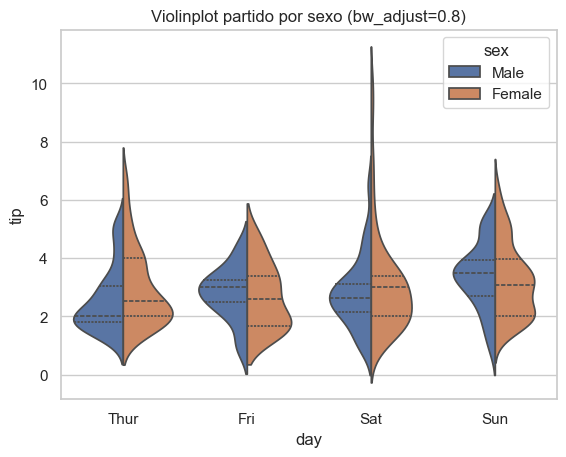

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")
tips = sns.load_dataset("tips")

sns.violinplot(
    data=tips,
    x="day", y="tip", hue="sex",
    split=True,         # violín “partido” por hue
    inner="quartile",
    bw_adjust=0.8       # suavizado (menor → más detalle)
)
plt.title("Violinplot partido por sexo (bw_adjust=0.8)")
plt.show()

C) Recortar colas y horizontal

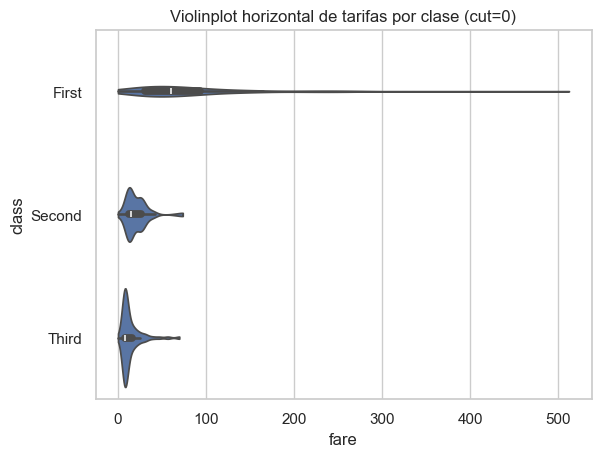

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")
titanic = sns.load_dataset("titanic").dropna(subset=["class", "fare"])

sns.violinplot(
    data=titanic, y="class", x="fare",
    cut=0, orient="h"      # cut=0 evita que la KDE se extienda más allá del rango
)
plt.title("Violinplot horizontal de tarifas por clase (cut=0)")
plt.show()

Notas: inner: "box", "quartile", "point" o None. split=True funciona cuando hue tiene dos categorías.

4.4 Diagramas de enjambre — swarmplot
Muestran cada punto (observación) evitando solapamiento con un algoritmo de enjambre. Útil para ver distribución + densidad local sin perder la granularidad.

A) Swarmplot básico

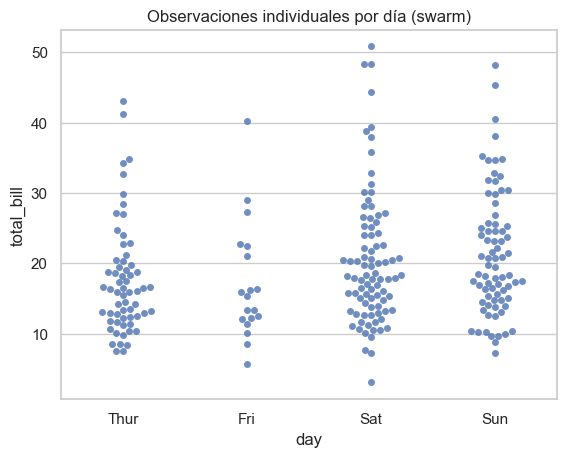

In [12]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")
tips = sns.load_dataset("tips")

sns.swarmplot(data=tips, x="day", y="total_bill", size=5, alpha=0.8)
plt.title("Observaciones individuales por día (swarm)")
plt.show()

B) Swarm por subgrupo y “dodge”

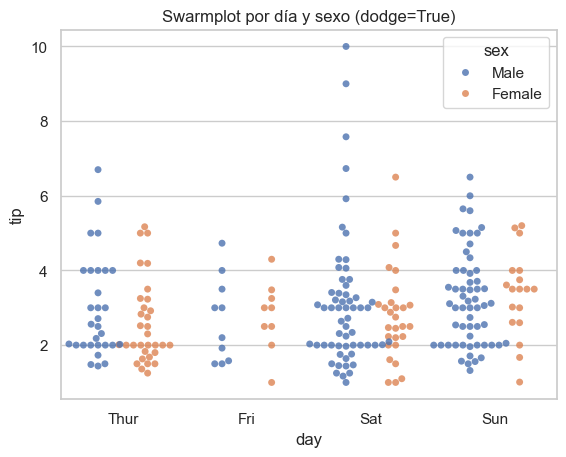

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")
tips = sns.load_dataset("tips")

sns.swarmplot(
    data=tips,
    x="day", y="tip",
    hue="sex",
    dodge=True,         # separa por subgrupo
    size=5, alpha=0.8
)
plt.title("Swarmplot por día y sexo (dodge=True)")
plt.show()

C) Combinar caja/violín + swarm (resumen + granularidad)

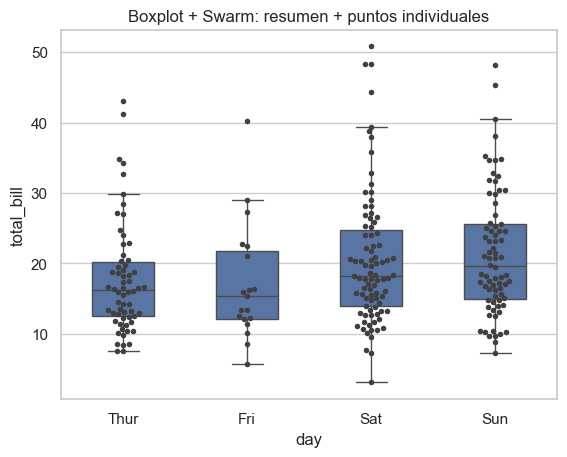

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")
tips = sns.load_dataset("tips")

ax = sns.boxplot(data=tips, x="day", y="total_bill", whis=1.5, width=0.5, fliersize=0)
sns.swarmplot(data=tips, x="day", y="total_bill", color="0.25", size=4, ax=ax)
plt.title("Boxplot + Swarm: resumen + puntos individuales")
plt.show()


Consejos: swarmplot puede ser costoso con miles de puntos. Para muchos datos, usar stripplot (más rápido) o muestras. Ajustá size, alpha y ancho del box/violín para evitar saturación visual.

4.5 Buenas prácticas y elección del gráfico
¿Promedios con error? → barplot.
¿Distribución robusta + outliers? → boxplot.
¿Forma completa de la distribución (multimodalidad)? → violinplot.
¿Mostrar todas las observaciones? → swarmplot (o stripplot si hay muchas).
Comparar subgrupos: usá hue o facetas con catplot(kind="box"/"violin"/"bar"/"swarm").
Orden natural: controla order/orient y considera escalas log si hay colas largas.
Color y accesibilidad: preferí paletas colorblind-friendly (sns.set_palette("deep") o "colorblind").
4.6 Bonus: catplot (nivel figura)
catplot crea grillas con cualquier gráfico categórico (facetas por filas/columnas).

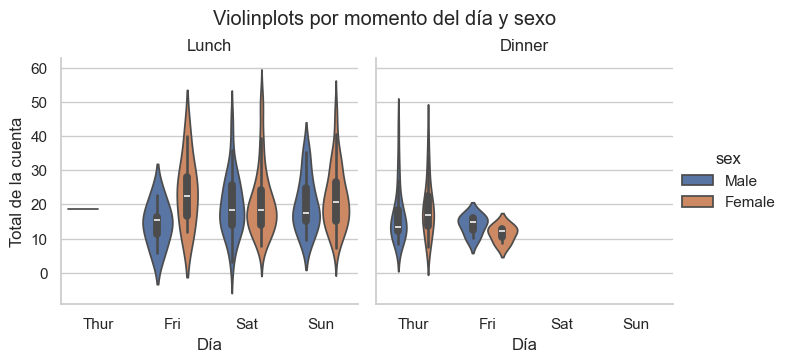

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_theme(style="whitegrid", context="notebook")
tips = sns.load_dataset("tips")

g = sns.catplot(
    data=tips,
    x="day", y="total_bill",
    hue="sex",
    col="time",            # Lunch vs Dinner en columnas
    kind="violin",         # 'bar' | 'box' | 'violin' | 'swarm' | 'strip' | 'boxen'
    split=False,
    height=3.5, aspect=1
)
g.set_axis_labels("Día", "Total de la cuenta")
g.set_titles("{col_name}")
plt.suptitle("Violinplots por momento del día y sexo", y=1.03)
plt.show()

Mini-checklist
¿Querés comparar promedios o medianas por categoría? Usá barplot.
¿Querés resumir distribución y outliers? Elegí boxplot.
¿Necesitás ver la forma completa de la distribución? Probá violinplot.
¿Querés mostrar cada observación individual? Usá swarmplot o stripplot.
¿Comparás subgrupos o muchas particiones? Combiná hue o catplot con facetas.